# Subgraph

A subgraph is a graph that is used as a node in another graph.

When adding subgraphs, you need to define how the parent graph and the subgraph communicate:
- **Invoke a graph from a node** — subgraphs are called from inside a node in the parent graph
- **Add a graph as a node** — a subgraph is added directly as a node in the parent and shares state keys with the parent


### Add a graph as a node

When the parent graph and subgraph can communicate over a shared state key (channel) in the schema, you can add a graph as a node in another graph. For example, in multi-agent systems, the agents often communicate over a shared messages key.

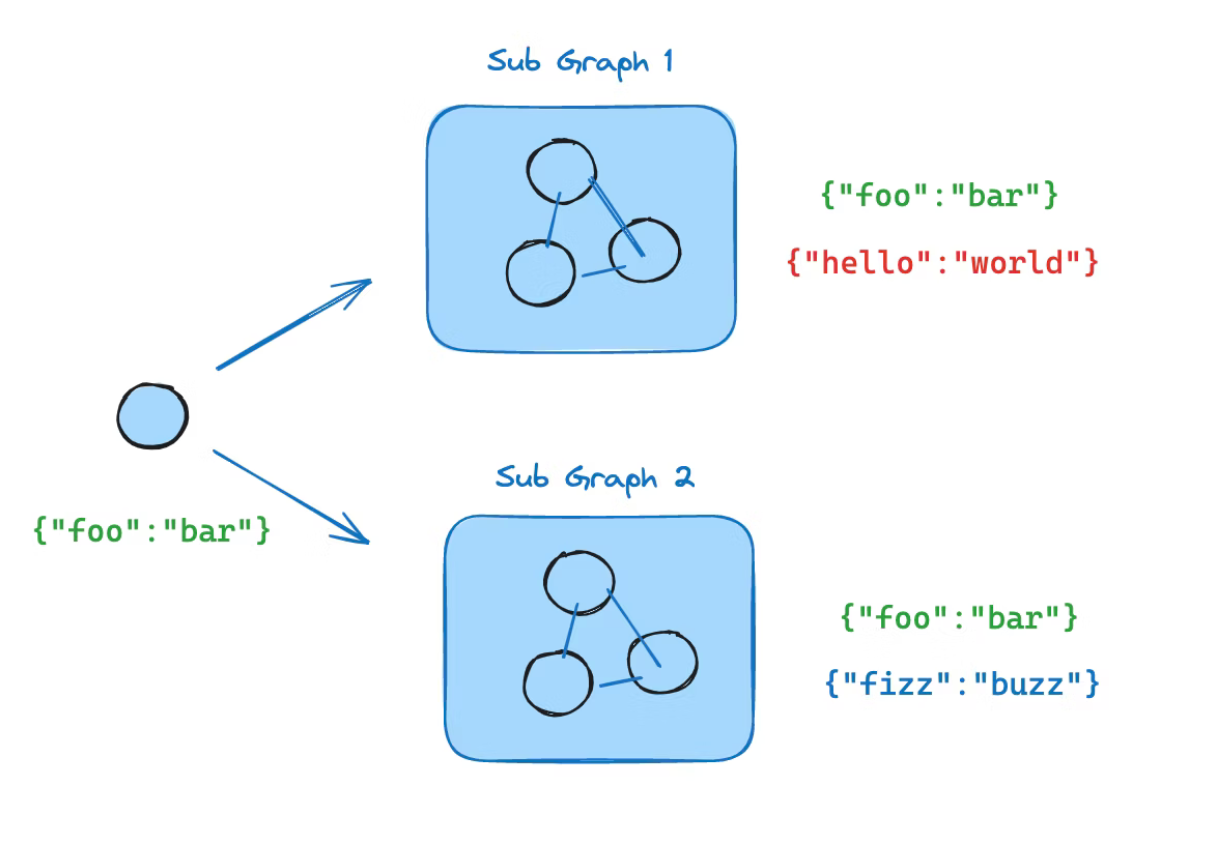

If your subgraph shares state keys with the parent graph, you can follow these steps to add it to your graph:
- Define the subgraph workflow (`subgraph_builder` in the example below) and compile it
- Pass compiled subgraph to the `add_node` method when defining the parent graph workflow


### Add persistence

Only need to provide the checkpointer when compiling the parent graph. LangGraph will automatically propagate the checkpointer to the child subgraphs.

### View subgraph state

When enable persistence, we can inspect the graph state (checkpoint) via the appropriate method. To view the subgraph state, you can use the subgraphs option. 

Inspect the graph state via `graph.get_state(config)`. To view the subgraph state, use `graph.get_state(config, subgraphs=True)`.

### Stream subgraph outputs

To include outputs from subgraphs in the streamed outputs, you can set the subgraphs option in the stream method of the parent graph. This will stream outputs from both the parent graph and any subgraphs.

```python
for chunk in graph.stream(
    {"foo": "foo"},
    subgraphs=True, 
    stream_mode="updates",
):
    print(chunk)